In [12]:
import pandas as pd
import glob
import os
import numpy as np
import ast
from scipy.stats import pearsonr, spearmanr
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.metrics.pairwise import cosine_similarity as sklearn_cossim
from collections import Counter

# Setting plot style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Inter', 'Roboto', 'Arial']

# Ensure output directory exists for plots
OUTPUT_DIR = "../results_rk/plots"
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

CONFIG = {
    'output_dir': OUTPUT_DIR
}

# --- HELPER METRICS ---
def mse(y_true, y_pred): return mean_squared_error(y_true, y_pred)
def rmse(y_true, y_pred): return np.sqrt(mean_squared_error(y_true, y_pred))
def mae(y_true, y_pred): return mean_absolute_error(y_true, y_pred)
def pearson_correlation(y_true, y_pred): 
     if len(y_true) < 2: return 0.0
     val, _ = pearsonr(y_true, y_pred)
     return val
def spearman_correlation(y_true, y_pred): 
     if len(y_true) < 2: return 0.0
     val, _ = spearmanr(y_true, y_pred)
     return val
def cosine_similarity(y_true, y_pred): 
     denom = (np.linalg.norm(y_true) * np.linalg.norm(y_pred))
     return np.dot(y_true, y_pred) / denom if denom > 0 else 0.0

def compute_protein_wise_metrics_all(y_true, y_pred):
    n_prots = y_true.shape[1]
    results = {
        'PCC': np.zeros(n_prots),
        'MSE': np.zeros(n_prots),
        'MAE': np.zeros(n_prots),
        'R2': np.zeros(n_prots),
        'Cosine': np.zeros(n_prots)
    }
    
    for i in range(n_prots):
        yt = y_true[:, i]
        yp = y_pred[:, i]
        mask = (~np.isnan(yt)) & (~np.isnan(yp))
        
        if mask.sum() > 2:
            r, _ = pearsonr(yt[mask], yp[mask])
            results['PCC'][i] = r
            results['MSE'][i] = mean_squared_error(yt[mask], yp[mask])
            results['MAE'][i] = mean_absolute_error(yt[mask], yp[mask])
            results['R2'][i] = r2_score(yt[mask], yp[mask])
            denom = (np.linalg.norm(yp[mask]) * np.linalg.norm(yt[mask]))
            results['Cosine'][i] = np.dot(yp[mask], yt[mask]) / denom if denom > 0 else 0.0
        else:
            results['PCC'][i] = 0.0
            results['MSE'][i] = np.nan
            results['MAE'][i] = np.nan
            results['R2'][i] = np.nan
            results['Cosine'][i] = 0.0
            
    return results


In [13]:
RESULTS_DIR = "../results_rk"
VAL_DATA_DIR = "../val_data"


In [14]:
# Find all protein_best.csv files from validation training
best_files = glob.glob(os.path.join(RESULTS_DIR, "*_best.csv"))
print(f"Found {len(best_files)} individual best files.")

dfs = []
for f in best_files:
    try:
        df = pd.read_csv(f)
        dfs.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs:
    df_best_all = pd.concat(dfs, ignore_index=True)
    df_best_all.sort_values("protein", inplace=True)
    df_best_all.reset_index(drop=True, inplace=True)
    print(f"Concatenated Best Models Shape: {df_best_all.shape}")
else:
    df_best_all = pd.DataFrame()
    print("No best files loaded.")


Found 600 individual best files.
Concatenated Best Models Shape: (600, 7)


In [15]:
datasets = ['iTRAQ', 'LabelFree', 'TMT']
all_results = {}

for ds in datasets:
    RNA_PATH = os.path.join(VAL_DATA_DIR, f"{ds}_transcriptomics.joblib")
    PROT_PATH = os.path.join(VAL_DATA_DIR, f"{ds}_proteomics.joblib")
    
    if not (os.path.exists(RNA_PATH) and os.path.exists(PROT_PATH)):
        print(f"Skipping {ds}: files not found.")
        continue
        
    print(f"\nProcessing {ds} dataset...")
    rna_df = joblib.load(RNA_PATH)
    prot_df = joblib.load(PROT_PATH)
    
    # Pre-process RNA: Ensure no NaNs in input
    rna_z = rna_df.fillna(0)
    available_feats = set(rna_z.columns)
    
    ds_predictions = []
    ds_true_values = []
    valid_proteins = []
    
    missing_warned = False
    
    # Prediction loop
    for _, row in df_best_all.iterrows():
        p_name = row['protein']
        if p_name not in prot_df.columns:
            continue
            
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # FIX: Check for missing features and impute 0
        current_missing = [f for f in needed_feats if f not in available_feats]
        
        if current_missing:
            if not missing_warned:
                print(f"  Warning: Missing features detected for {p_name} (and possibly others). Imputing 0.")
                missing_warned = True
            
            # Create a temporary X vector
            present_feats = [f for f in needed_feats if f in available_feats]
            
            if not present_feats and not current_missing: # Should not happen if needed_feats is empty
                 X_vals = np.zeros((rna_z.shape[0], 0))
            else:
                 weights_present = np.array([coeffs[f] for f in needed_feats if f in available_feats])
                 X_present = rna_z[present_feats]
                 y_pred = X_present.dot(weights_present)
                 
        else:
            # Standard path (all features present)
            weights = np.array([coeffs[f] for f in needed_feats])
            X = rna_z[needed_feats]
            y_pred = X.dot(weights)
            
        y_true = prot_df[p_name]
        
        valid_proteins.append(p_name)
        ds_predictions.append(y_pred.values)
        ds_true_values.append(y_true.values)
        
    if not valid_proteins:
        print(f"No valid protein models found for {ds}")
        continue
        
    # (Samples x Proteins) matrices
    y_pred_mat = np.array(ds_predictions).T
    y_true_mat = np.array(ds_true_values).T
    
    # Store DataFrames for detailed analysis later
    pred_df_full = pd.DataFrame(y_pred_mat, index=rna_df.index, columns=valid_proteins)
    true_df_full = pd.DataFrame(y_true_mat, index=rna_df.index, columns=valid_proteins)
    
    # Calculate sample-wise metrics
    mse_list, mae_list, pcc_list, r2_list, cos_list = [], [], [], [], []
    for i in range(y_pred_mat.shape[0]):
        yp = y_pred_mat[i]
        yt = y_true_mat[i]
        mask = (~np.isnan(yt)) & (~np.isnan(yp))
        if mask.sum() > 2:
            mse_list.append(np.mean((yp[mask] - yt[mask])**2))
            mae_list.append(np.mean(np.abs(yp[mask] - yt[mask])))
            r, _ = pearsonr(yp[mask], yt[mask])
            pcc_list.append(r)
            r2_list.append(r2_score(yt[mask], yp[mask]))
            denom = (np.linalg.norm(yp[mask]) * np.linalg.norm(yt[mask]))
            cos_list.append(np.dot(yp[mask], yt[mask]) / denom if denom > 0 else 0.0)
        else:
            for l in [mse_list, mae_list, pcc_list, r2_list, cos_list]: l.append(np.nan)
            
    # Calculate protein-wise metrics (ALL)
    prot_metrics = compute_protein_wise_metrics_all(y_true_mat, y_pred_mat)
    
    all_results[ds] = {
        'protein_metrics': prot_metrics,
        'metrics': { # Sample-wise mean metrics
            'MSE': np.array(mse_list),
            'MAE': np.array(mae_list),
            'PCC': np.array(pcc_list),
            'R2': np.array(r2_list),
            'Cosine': np.array(cos_list)
        },
        'samples': rna_df.index.tolist(),
        'proteins': valid_proteins,
        'predictions_df': pred_df_full,
        'ground_truth_df': true_df_full
    }
    
    print(f"Done. Predicted {y_pred_mat.shape[1]} proteins across {y_pred_mat.shape[0]} samples.")



Processing iTRAQ dataset...
Done. Predicted 600 proteins across 276 samples.

Processing LabelFree dataset...
Done. Predicted 600 proteins across 360 samples.

Processing TMT dataset...
Done. Predicted 600 proteins across 1924 samples.


In [16]:
# Create Summary Table
summary_data = []
for ds, res in all_results.items():
    stats = {
        'Dataset': ds,
        'Proteins': len(res['proteins']),
        'Samples': len(res['samples']),
        'Mean PCC (Sample)': np.nanmean(res['metrics']['PCC']),
        'Mean R2': np.nanmean(res['metrics']['R2']),
        'Mean Protein PCC': np.nanmean(res['protein_metrics']['PCC']),
        'Mean Cosine': np.nanmean(res['metrics']['Cosine']),
        'Mean MSE': np.nanmean(res['metrics']['MSE'])
    }
    summary_data.append(stats)

summary_df = pd.DataFrame(summary_data)
print("=== Overall Summary Statistics ===")
display(summary_df.round(4))


=== Overall Summary Statistics ===


,Dataset,Proteins,Samples,Mean PCC (Sample),Mean R2,Mean Protein PCC,Mean Cosine,Mean MSE
0,iTRAQ,600,276,0.0052,-0.0185,0.0204,0.0110,0.3340
1,LabelFree,600,360,0.0207,-0.0031,0.0280,0.0213,0.9425
2,TMT,600,1924,-0.0083,-5.7733,-0.0087,-0.0139,10.1622



=== Detailed Tissue Metrics by Dataset ===
  Dataset          Tissue       R2  Cosine     MSE
    iTRAQ     BREAST_2016  -0.0147  0.0135  0.3353
    iTRAQ      OVARY_2016  -0.0095  0.0045  0.3227
    iTRAQ    STOMACH_2019  -0.0355  0.0181  0.3495
LabelFree           BRAIN  -0.0006  0.0433  0.7888
LabelFree           COLON  -0.0083  0.0193  0.7440
LabelFree           LIVER  -0.0010 -0.0081  1.2982
LabelFree            LUNG  -0.0007  0.0268  1.0487
LabelFree        PROSTATE  -0.0038  0.0215  0.9094
      TMT      BRAIN_2021  -4.1929  0.0301  3.3695
      TMT      BREAST2020  -1.4477 -0.0634  4.6482
      TMT      COLON_2019  -4.0066  0.0600  3.5658
      TMT     ENDOMET_VAL  -4.8865  0.0223  3.3205
      TMT   HEADNECK_2021 -13.5662 -0.0713 28.3532
      TMT       LIVER_VAL  -4.4959 -0.0413  3.5700
      TMT        LUNG2021  -1.4979  0.0605  4.7949
      TMT LUNG_2020_SMOKE  -3.5893 -0.0963  2.7537
      TMT        LUNG_VAL  -1.3996  0.0412  4.5309
      TMT     PANCREA2021 -10.5092 -0.

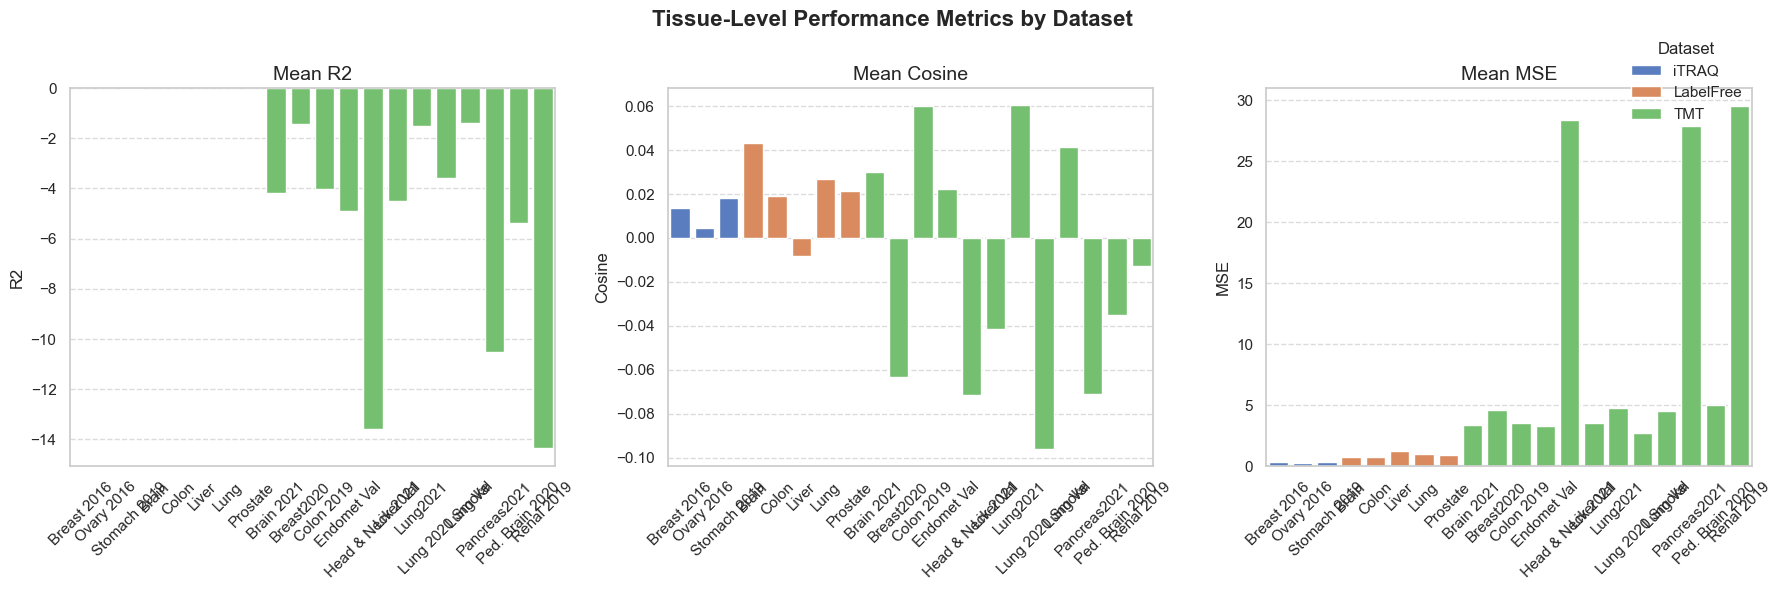

In [17]:
def get_tissue(sample_name):
    parts = sample_name.rsplit('_', 1)
    if len(parts) == 2 and parts[1].isdigit(): return parts[0]
    return sample_name

def _display(t):
    return (t.replace('_', ' ').replace('HEADNECK', 'Head & Neck').replace('PANCREA', 'Pancreas').replace('PEDBRAIN', 'Ped. Brain').title())

tissue_data = []
for ds, res in all_results.items():
    samples = res['samples']
    tissues = [get_tissue(s) for s in samples]
    metrics = res['metrics']
    
    df_ds = pd.DataFrame({
        'Tissue': tissues,
        'R2': metrics['R2'],
        'Cosine': metrics['Cosine'],
        'MSE': metrics['MSE']
    })
    
    tissue_means = df_ds.groupby('Tissue').mean(numeric_only=True).reset_index()
    tissue_means['Dataset'] = ds 
    tissue_data.append(tissue_means)

all_tissue_df = pd.concat(tissue_data, ignore_index=True)
all_tissue_df['Tissue Display'] = all_tissue_df['Tissue'].apply(_display)

print("\n=== Detailed Tissue Metrics by Dataset ===")
print(all_tissue_df[['Dataset', 'Tissue', 'R2', 'Cosine', 'MSE']].round(4).to_string(index=False))

metrics_to_plot = ['R2', 'Cosine', 'MSE']
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Tissue-Level Performance Metrics by Dataset', fontsize=16, fontweight='bold')

for i, metric in enumerate(metrics_to_plot):
    ax = axes[i]
    sns.barplot(data=all_tissue_df, x='Tissue Display', y=metric, hue='Dataset', ax=ax, palette='muted')
    ax.set_title(f'Mean {metric}', fontsize=14)
    ax.set_xlabel('')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    if i > 0: 
        ax.get_legend().remove() 
    
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    if ax.get_legend(): ax.get_legend().remove()

fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.98, 0.95), title='Dataset')
plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.savefig(os.path.join(CONFIG['output_dir'], 'tissue_metrics_grid.png'), dpi=150)
plt.show()



  PROTEIN-LEVEL DEEP DIVE


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\898447017.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = ax.boxplot(data_for_box, labels=labels_for_box, patch_artist=True, medianprops=dict(color='black'))
C:\Users\hp\AppData\Local\Temp\ipykernel_41208\898447017.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = ax.boxplot(data_for_box, labels=labels_for_box, patch_artist=True, medianprops=dict(color='black'))
C:\Users\hp\AppData\Local\Temp\ipykernel_41208\898447017.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = ax.boxplot(data_for_box, labels=labels_for_box, patch_artist=True, medi

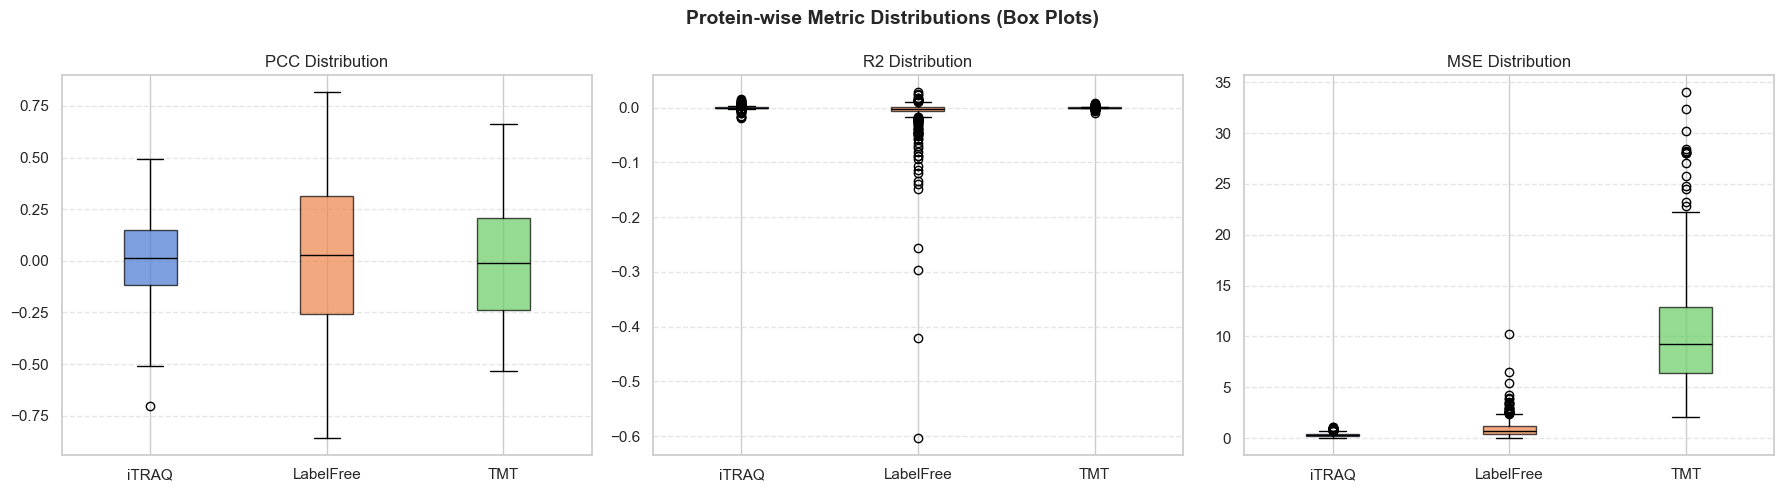

In [18]:
# === Protein-Level Performance Analysis ===
print("\n" + "="*50)
print("  PROTEIN-LEVEL DEEP DIVE")
print("="*50)

metrics_to_show = ['PCC', 'R2', 'MSE']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Protein-wise Metric Distributions (Box Plots)', fontsize=14, fontweight='bold')

for i, metric in enumerate(metrics_to_show):
    ax = axes[i]
    data_for_box = []
    labels_for_box = []
    
    for ds in datasets:
        if ds in all_results:
            vals = all_results[ds]['protein_metrics'][metric]
            vals = vals[~np.isnan(vals)]
            data_for_box.append(vals)
            labels_for_box.append(ds)
            
    colors = sns.color_palette("muted", len(labels_for_box))
    bplot = ax.boxplot(data_for_box, labels=labels_for_box, patch_artist=True, medianprops=dict(color='black'))
    
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    ax.set_title(f'{metric} Distribution')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.savefig(os.path.join(CONFIG['output_dir'], 'protein_metric_distributions.png'), dpi=150)
plt.show()



##############################
 dataset: iTRAQ
##############################

--- Metric: PCC (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


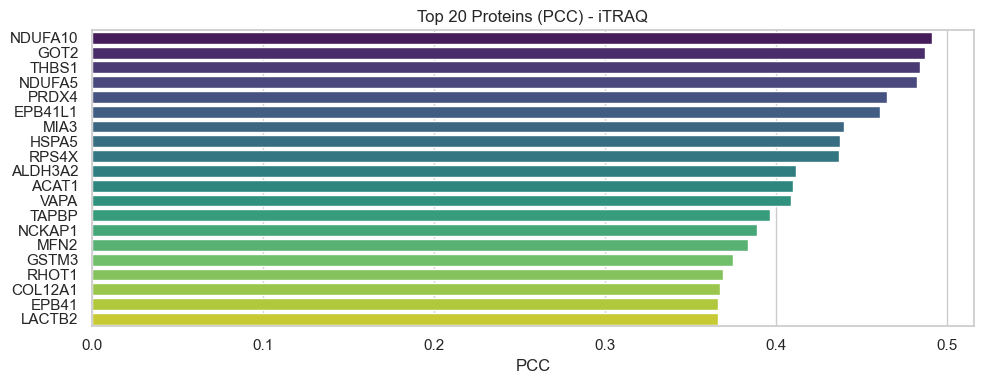

Top 100 PCC (Showing first 10):
   Rank  Protein     Value
0     1  NDUFA10  0.491271
1     2     GOT2  0.487027
2     3    THBS1  0.484389
3     4   NDUFA5  0.482245
4     5    PRDX4  0.464895
5     6  EPB41L1  0.461005
6     7     MIA3  0.439650
7     8    HSPA5  0.437621
8     9    RPS4X  0.436823
9    10  ALDH3A2  0.411827

--- Metric: MSE (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


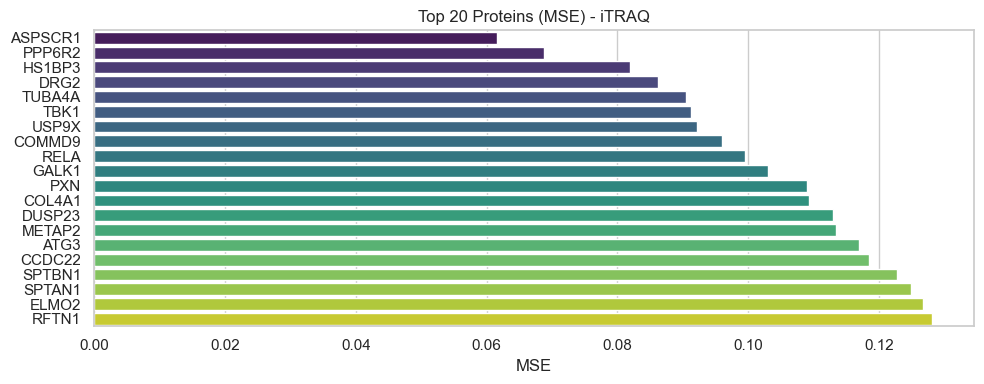

Top 100 MSE (Showing first 10):
   Rank  Protein     Value
0     1  ASPSCR1  0.061611
1     2   PPP6R2  0.068748
2     3   HS1BP3  0.081991
3     4     DRG2  0.086247
4     5   TUBA4A  0.090518
5     6     TBK1  0.091252
6     7    USP9X  0.092237
7     8   COMMD9  0.096083
8     9     RELA  0.099592
9    10    GALK1  0.102968

--- Metric: Cosine (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


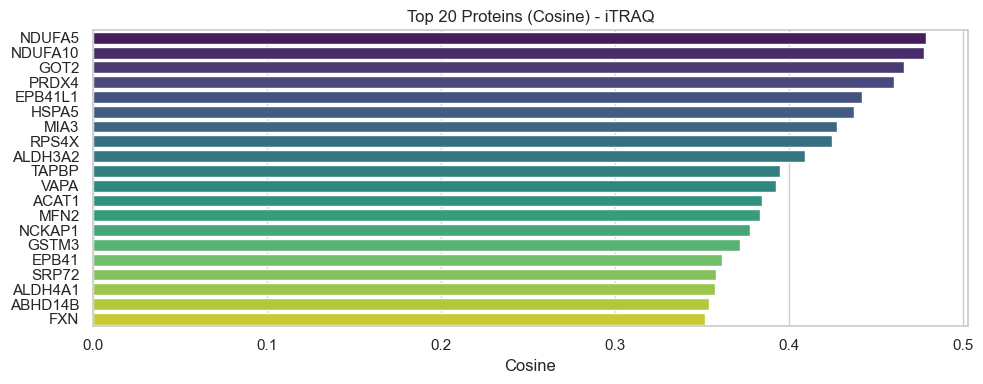

Top 100 Cosine (Showing first 10):
   Rank  Protein     Value
0     1   NDUFA5  0.479036
1     2  NDUFA10  0.477982
2     3     GOT2  0.466319
3     4    PRDX4  0.460619
4     5  EPB41L1  0.442283
5     6    HSPA5  0.437348
6     7     MIA3  0.427837
7     8    RPS4X  0.424701
8     9  ALDH3A2  0.409204
9    10    TAPBP  0.395145

##############################
 dataset: LabelFree
##############################

--- Metric: PCC (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


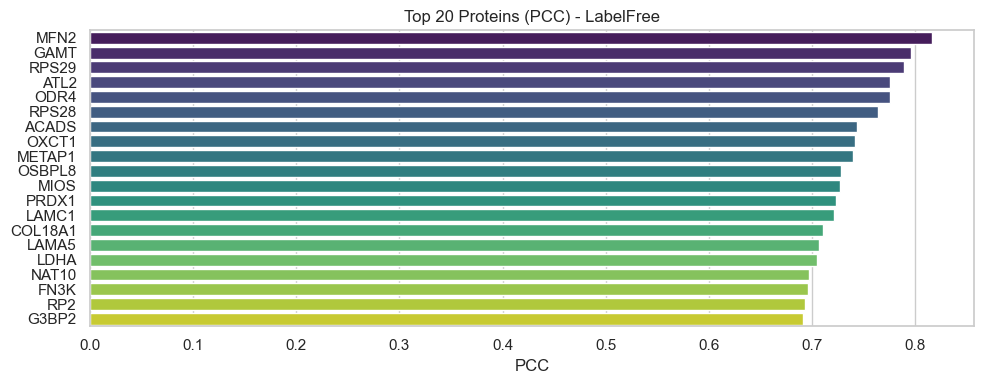

Top 100 PCC (Showing first 10):
   Rank Protein     Value
0     1    MFN2  0.816453
1     2    GAMT  0.796374
2     3   RPS29  0.789568
3     4    ATL2  0.776095
4     5    ODR4  0.775816
5     6   RPS28  0.763876
6     7   ACADS  0.743391
7     8   OXCT1  0.742114
8     9  METAP1  0.739713
9    10  OSBPL8  0.727990

--- Metric: MSE (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


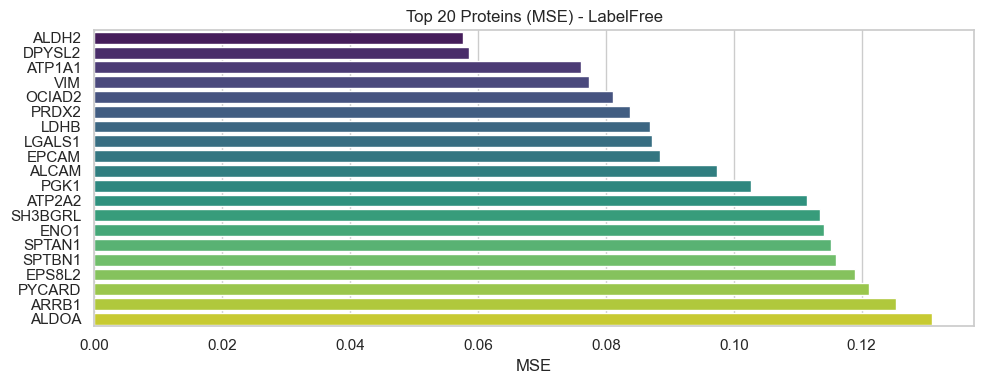

Top 100 MSE (Showing first 10):
   Rank Protein     Value
0     1   ALDH2  0.057695
1     2  DPYSL2  0.058624
2     3  ATP1A1  0.076040
3     4     VIM  0.077285
4     5  OCIAD2  0.081075
5     6   PRDX2  0.083707
6     7    LDHB  0.086880
7     8  LGALS1  0.087267
8     9   EPCAM  0.088472
9    10   ALCAM  0.097381

--- Metric: Cosine (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


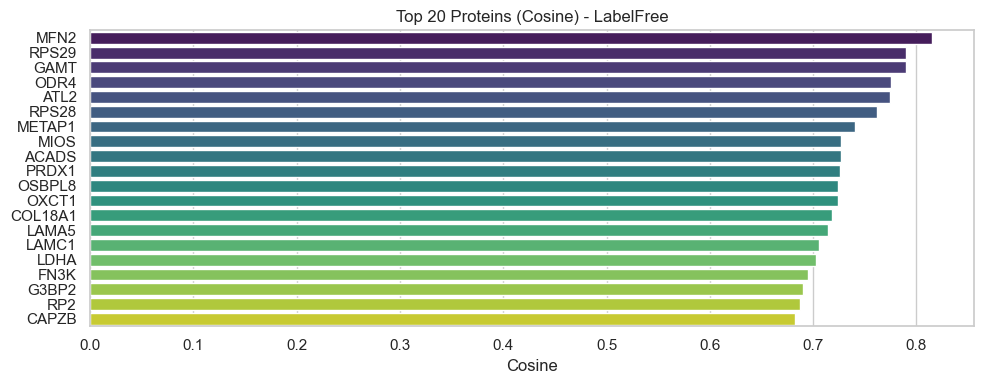

Top 100 Cosine (Showing first 10):
   Rank Protein     Value
0     1    MFN2  0.815015
1     2   RPS29  0.789733
2     3    GAMT  0.789479
3     4    ODR4  0.775734
4     5    ATL2  0.774410
5     6   RPS28  0.761809
6     7  METAP1  0.740721
7     8    MIOS  0.726664
8     9   ACADS  0.726602
9    10   PRDX1  0.725632

##############################
 dataset: TMT
##############################

--- Metric: PCC (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


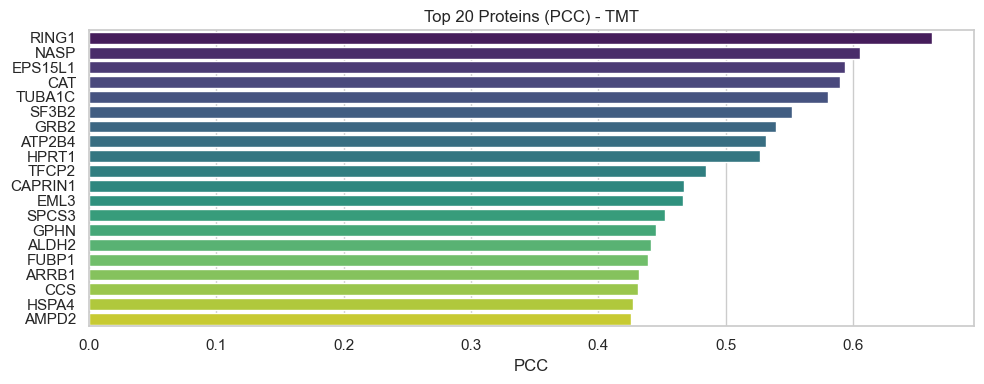

Top 100 PCC (Showing first 10):
   Rank  Protein     Value
0     1    RING1  0.662067
1     2     NASP  0.605918
2     3  EPS15L1  0.593975
3     4      CAT  0.590105
4     5   TUBA1C  0.580657
5     6    SF3B2  0.551925
6     7     GRB2  0.539639
7     8   ATP2B4  0.531840
8     9    HPRT1  0.527325
9    10    TFCP2  0.484851

--- Metric: MSE (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


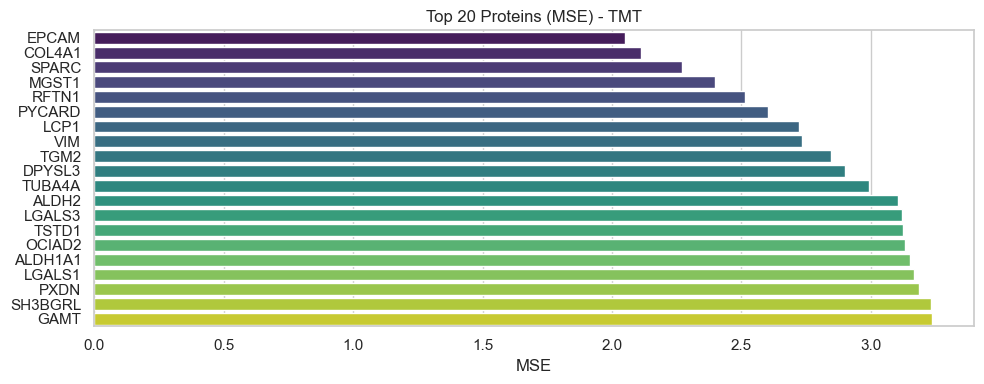

Top 100 MSE (Showing first 10):
   Rank Protein     Value
0     1   EPCAM  2.048481
1     2  COL4A1  2.110424
2     3   SPARC  2.270630
3     4   MGST1  2.399294
4     5   RFTN1  2.513723
5     6  PYCARD  2.603966
6     7    LCP1  2.721104
7     8     VIM  2.735677
8     9    TGM2  2.845542
9    10  DPYSL3  2.899677

--- Metric: Cosine (Top 20) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_41208\273169462.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")


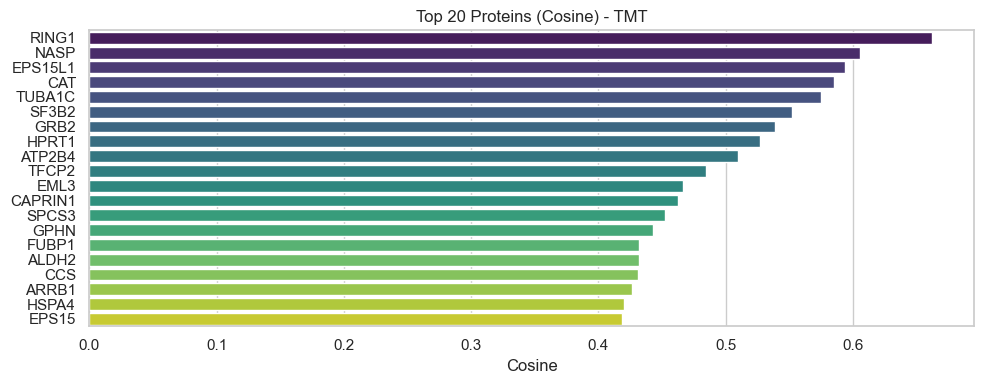

Top 100 Cosine (Showing first 10):
   Rank  Protein     Value
0     1    RING1  0.661882
1     2     NASP  0.605768
2     3  EPS15L1  0.593378
3     4      CAT  0.585092
4     5   TUBA1C  0.574490
5     6    SF3B2  0.551880
6     7     GRB2  0.538871
7     8    HPRT1  0.527094
8     9   ATP2B4  0.509567
9    10    TFCP2  0.484421


In [19]:
# === Top 100 Proteins Analysis ===
# For each dataset and each metric (PCC, MSE, Cosine for comparison saving)
metrics_for_saving = ['PCC', 'MSE', 'Cosine']

def get_top_100(proteins, values, metric_name='PCC'):
    # Filter NaNs
    valid_mask = ~np.isnan(values)
    prots = np.array(proteins)[valid_mask]
    vals = values[valid_mask]
    
    # Sort
    if metric_name in ['MSE', 'MAE']:
        # Ascending sort: smallest is best
        sorted_idx = np.argsort(vals)
    else:
        # Descending sort: largest is best
        sorted_idx = np.argsort(vals)[::-1]
        
    top_100_idx = sorted_idx[:100]
    return prots[top_100_idx], vals[top_100_idx]

for ds in datasets:
    if ds not in all_results: continue
    print(f"\n{'#'*30}\n dataset: {ds}\n{'#'*30}")
    
    res = all_results[ds]
    proteins = res['proteins']
    
    for metric in metrics_for_saving:
        vals = res['protein_metrics'][metric]
        top_p, top_v = get_top_100(proteins, vals, metric_name=metric)
        
        print(f"\n--- Metric: {metric} (Top 20) ---")
        
        # Plot Top 20
        plt.figure(figsize=(10, 4))
        sns.barplot(x=top_v[:20], y=top_p[:20], palette="viridis")
        plt.title(f"Top 20 Proteins ({metric}) - {ds}")
        plt.xlabel(metric)
        plt.tight_layout()
        plt.show()
        
        # DataFrame for user
        df_top = pd.DataFrame({'Rank': range(1, len(top_p)+1), 'Protein': top_p, 'Value': top_v})
        print(f"Top 100 {metric} (Showing first 10):")
        print(df_top.head(10))


In [20]:
# === Save Top 100 Lists to CSV (Uncomment to Run) ===
# for ds in datasets:
#     if ds not in all_results: continue
#     res = all_results[ds]
#     proteins = res['proteins']
#     for metric in ['PCC', 'MSE', 'Cosine']:
#         vals = res['protein_metrics'][metric]
#         top_p, top_v = get_top_100(proteins, vals, metric_name=metric)
#         df_top = pd.DataFrame({'Rank': range(1, len(top_p)+1), 'Protein': top_p, 'Value': top_v})
#         
#         safe_metric = metric.replace(' ', '_')
#         filename = os.path.join(CONFIG['output_dir'], f"top100_{ds}_{safe_metric}.csv")
#         df_top.to_csv(filename, index=False)
#         print(f"Saved {filename}")



Generating protein-centric plots for iTRAQ...
Saved: ../results_rk/plots\protein_overall_bar_iTRAQ.png


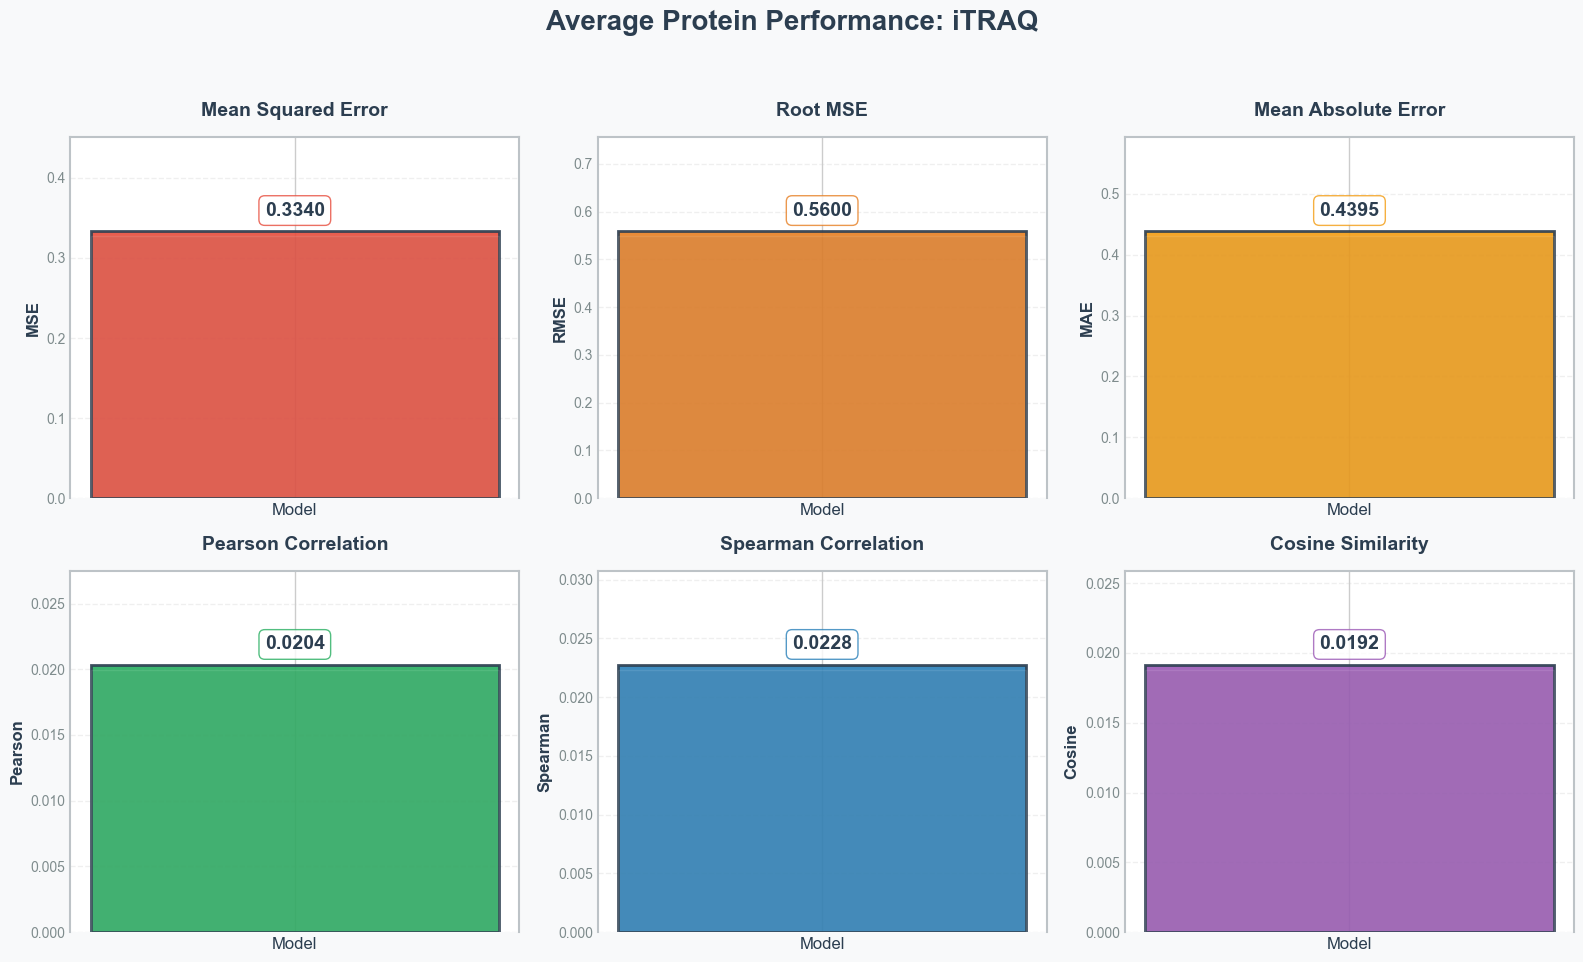

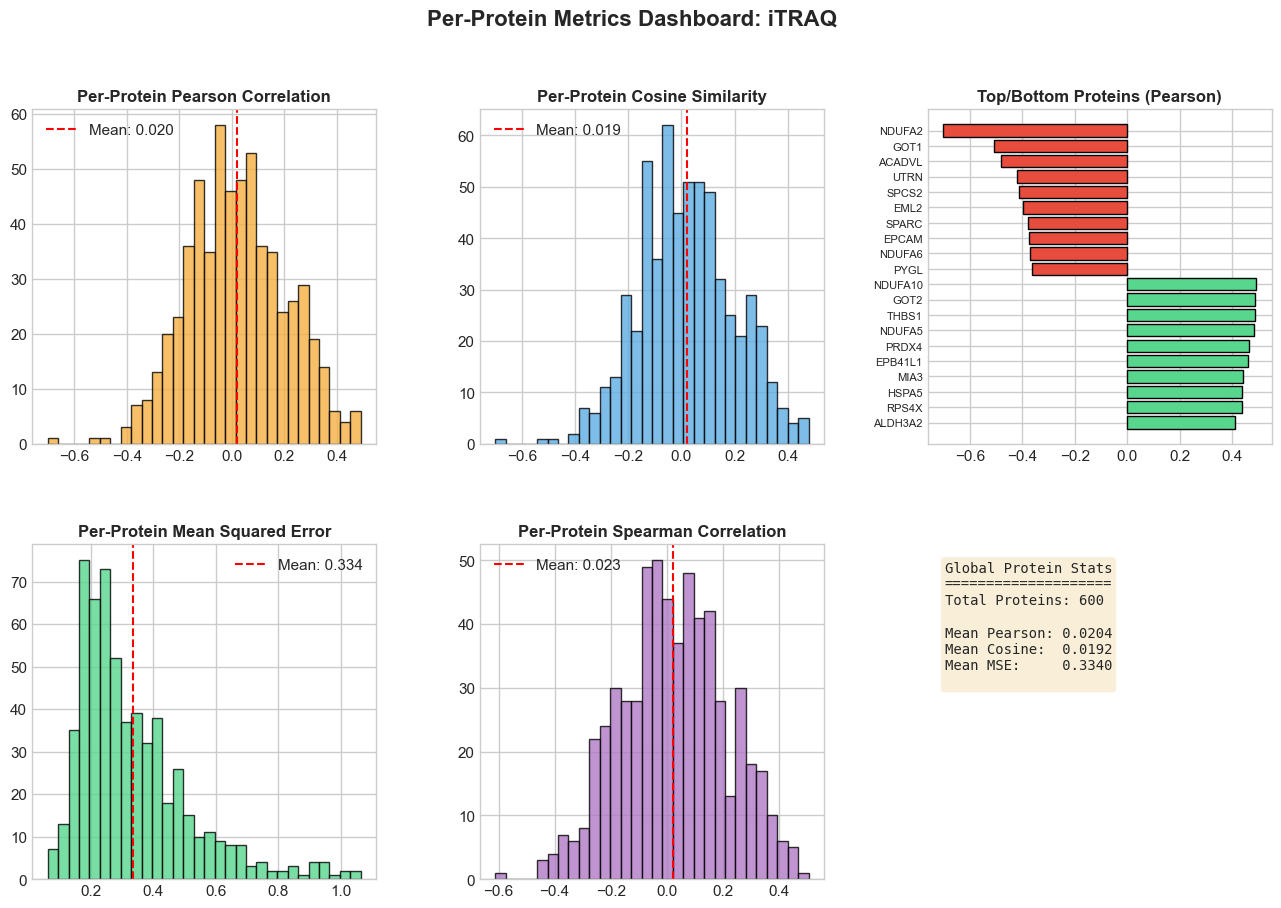


Generating protein-centric plots for LabelFree...
Saved: ../results_rk/plots\protein_overall_bar_LabelFree.png


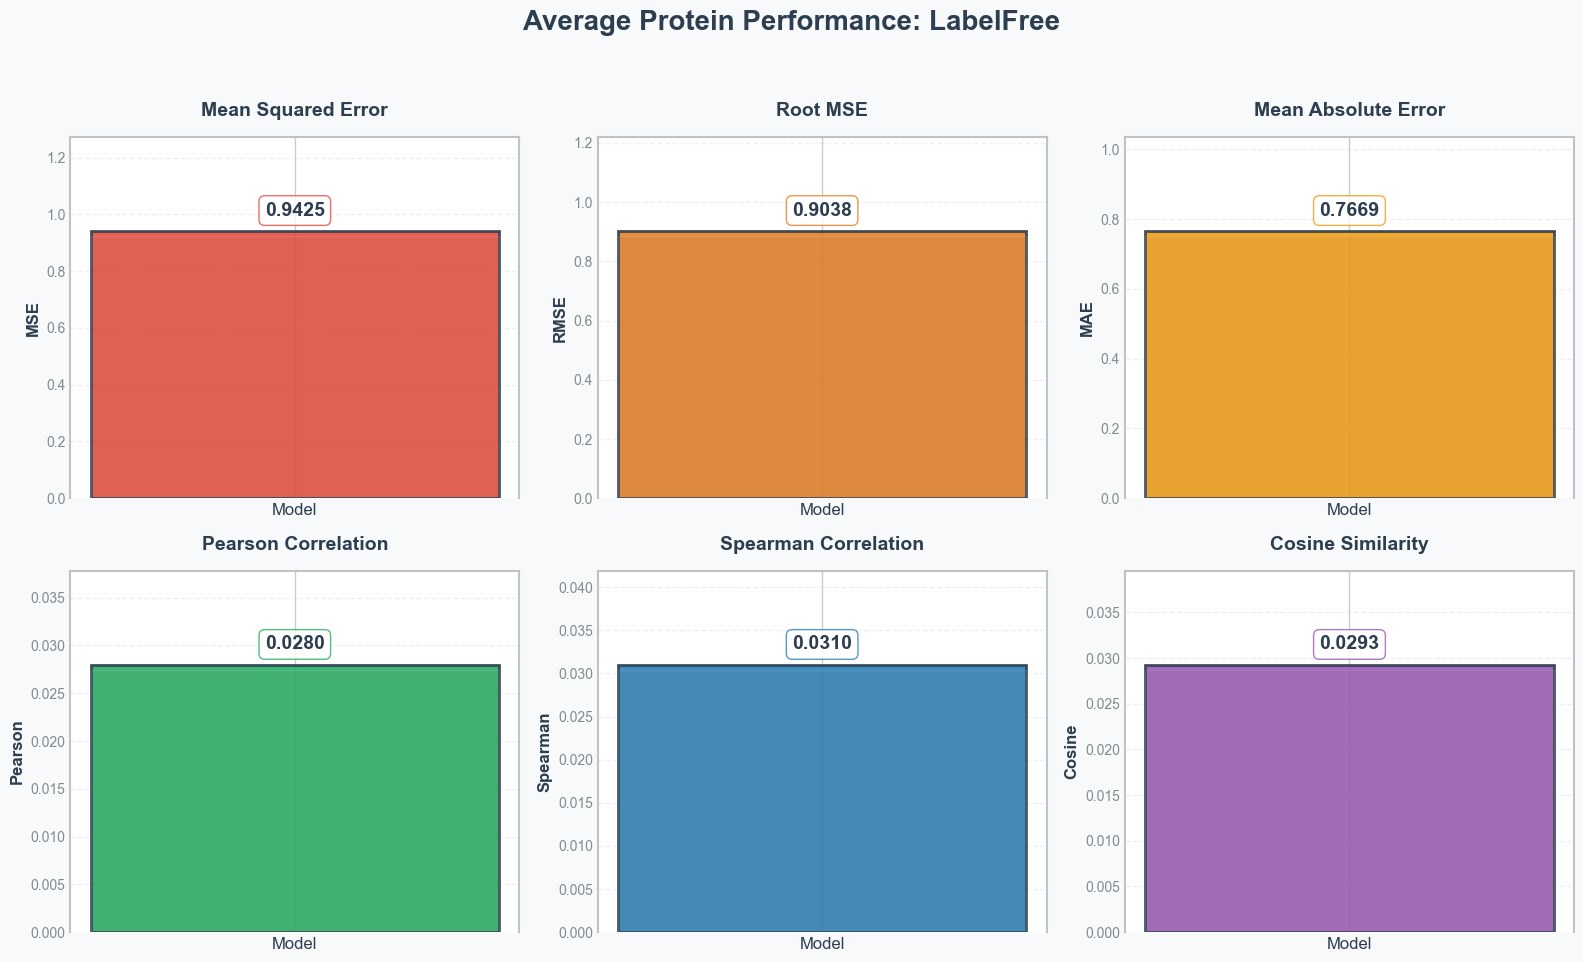

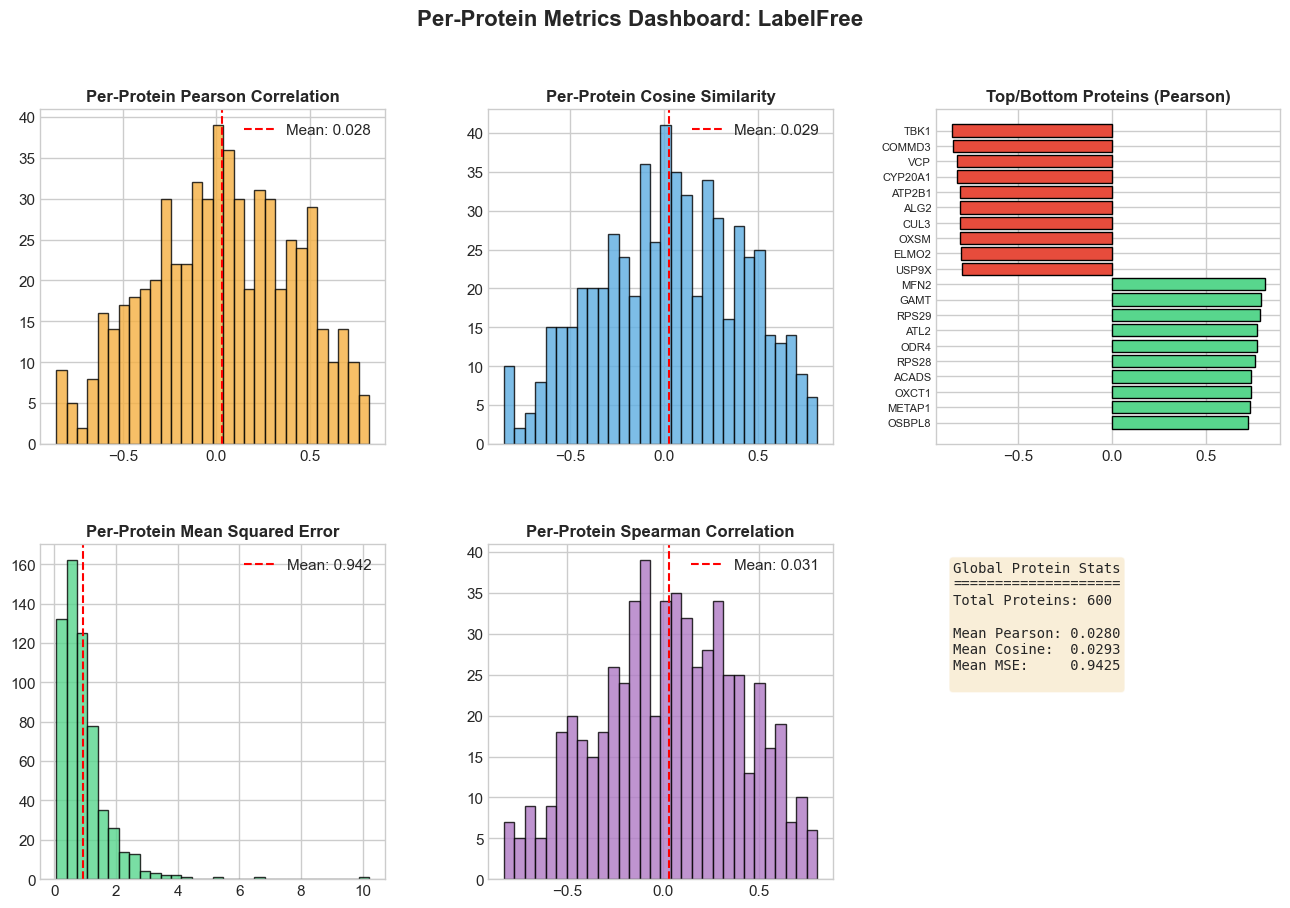


Generating protein-centric plots for TMT...
Saved: ../results_rk/plots\protein_overall_bar_TMT.png


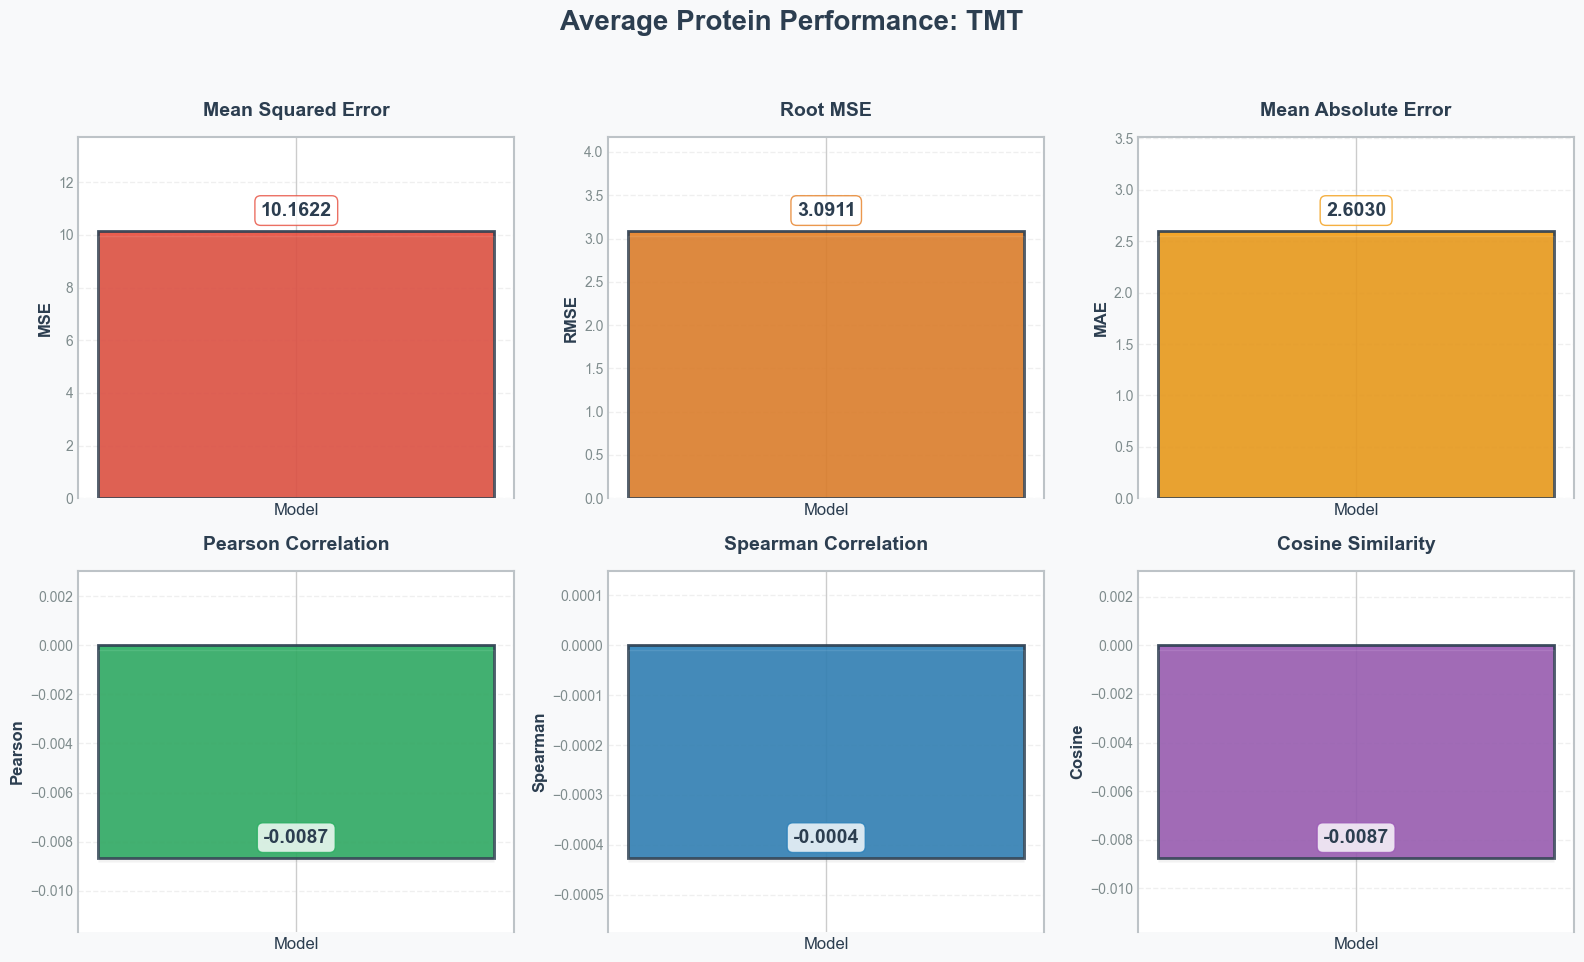

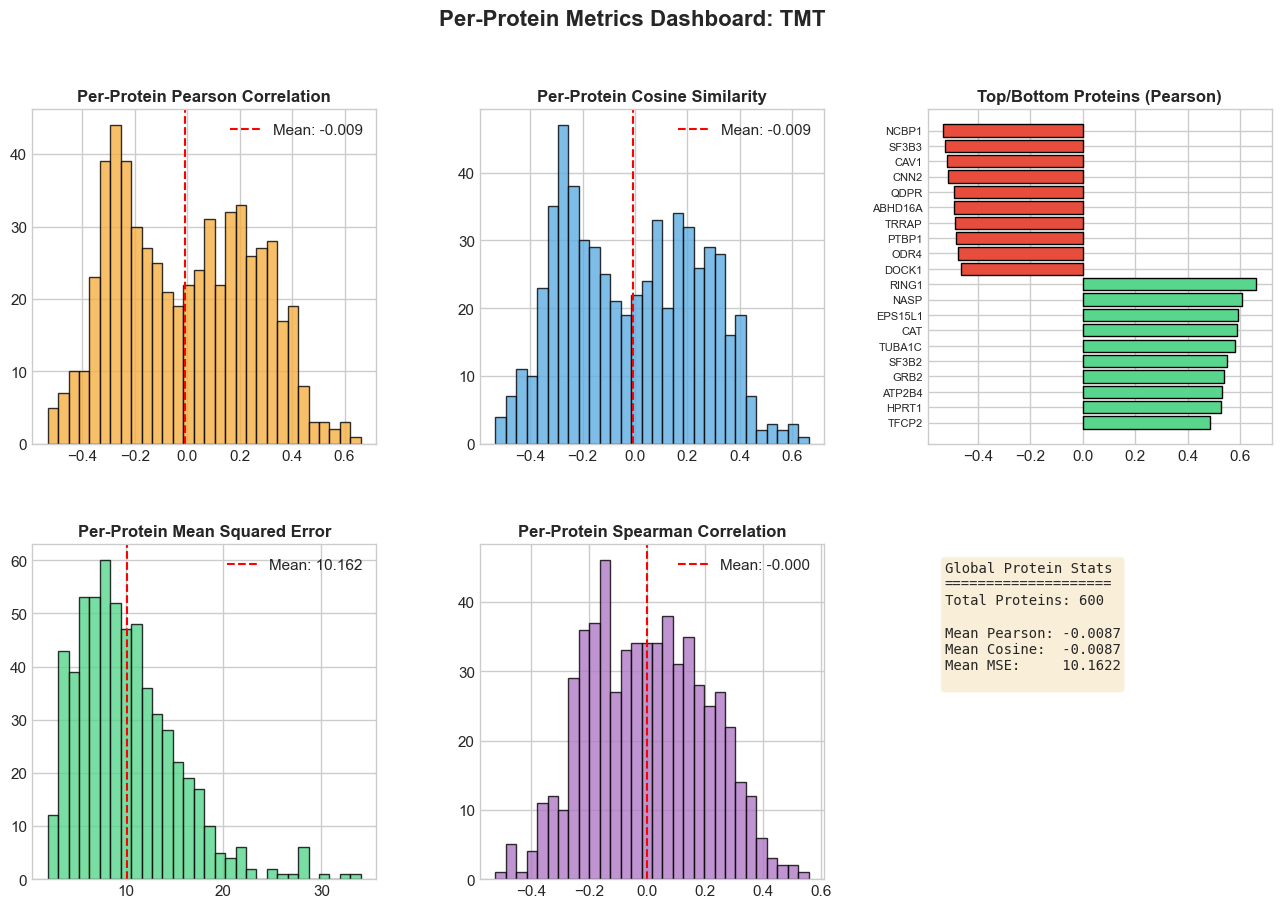

In [21]:
# === UPDATED DETAILED PLOTTING FUNCTIONS ===

# Re-defining plot_overall_bar to support the user's call pattern and data structure
def plot_overall_bar(mean_metrics, title, out_path):
    plt.style.use("seaborn-v0_8-whitegrid")

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.patch.set_facecolor("#F8F9FA")

    fig.suptitle(title, fontsize=20, fontweight="bold", color="#2C3E50", y=0.98)

    colors = ["#E74C3C", "#E67E22", "#F39C12", "#27AE60", "#2980B9", "#9B59B6"]
    # Keys from the user's new compute_mean_metrics
    plots = [
        ("Mean Squared Error", "MSE", mean_metrics.get("MSE", 0), colors[0]),
        ("Root MSE", "RMSE", mean_metrics.get("RMSE", 0), colors[1]),
        ("Mean Absolute Error", "MAE", mean_metrics.get("MAE", 0), colors[2]),
        ("Pearson Correlation", "Pearson", mean_metrics.get("Pearson", 0), colors[3]),
        ("Spearman Correlation", "Spearman", mean_metrics.get("Spearman", 0), colors[4]),
        ("Cosine Similarity", "Cosine", mean_metrics.get("Cosine", 0), colors[5]),
    ]

    for idx, (t, ylabel, value, color) in enumerate(plots):
        row, col = divmod(idx, 3)
        ax = axes[row, col]
        ax.set_facecolor("#FFFFFF")

        if np.isnan(value): value = 0.0

        bar = ax.bar(["Model"], [value], color=color, width=0.6,
                     edgecolor="#2C3E50", linewidth=2, alpha=0.9)

        ax.bar(["Model"], [value], color="gray", width=0.6, alpha=0.1,
               bottom=-value * 0.02 if value > 0 else value * 0.02)

        for rect in bar:
            height = rect.get_height()
            ax.annotate(
                f"{value:.4f}",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=14,
                fontweight="bold",
                color="#2C3E50",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=color, alpha=0.8),
            )

        ax.set_title(t, fontsize=14, fontweight="bold", color="#2C3E50", pad=15)
        ax.set_ylabel(ylabel, fontsize=12, fontweight="bold", color="#2C3E50")

        # Dynamic ylim
        if abs(value) < 1e-9:
             ax.set_ylim(0, 1)
        elif value >= 0:
            ax.set_ylim(0, value * 1.35)
        else:
            ax.set_ylim(value * 1.35, abs(value) * 0.35)

        ax.tick_params(axis="x", labelsize=12, colors="#2C3E50")
        ax.tick_params(axis="y", labelsize=10, colors="#7F8C8D")
        ax.yaxis.grid(True, linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_color("#BDC3C7")
            spine.set_linewidth(1.5)
        ax.spines["bottom"].set_visible(False)

    plt.tight_layout(rect=[0, 0.02, 1, 0.95])
    plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved: {out_path}")
    plt.show()

def compute_mean_metrics(ground_truth, predictions):
    # Calculates mean metrics across PROTEINS (instead of samples)
    metrics_per_protein = {
        "MSE": [], "RMSE": [], "MAE": [],
        "Pearson": [], "Spearman": [], "Cosine": []
    }

    # Iterate over columns (Proteins)
    for protein in predictions.columns:
        y_true = ground_truth[protein].values.astype(float)
        y_pred = predictions[protein].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 1: # Pearson/Spearman need at least 2 points
            metrics_per_protein["MSE"].append(mse(y_true_clean, y_pred_clean))
            metrics_per_protein["RMSE"].append(rmse(y_true_clean, y_pred_clean))
            metrics_per_protein["MAE"].append(mae(y_true_clean, y_pred_clean))
            metrics_per_protein["Pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))
            metrics_per_protein["Spearman"].append(spearman_correlation(y_true_clean, y_pred_clean))
            metrics_per_protein["Cosine"].append(cosine_similarity(y_true_clean, y_pred_clean))

    return {k: np.nanmean(v) for k, v in metrics_per_protein.items()}

def compute_detailed_tables(ground_truth, predictions):
    # Generates per-protein stats for all metrics
    # Now storing EVERYTHING per protein
    per_protein = {
        "protein": [], "cosine": [], "pearson": [], 
        "spearman": [], "mse": [], "mae": []
    }
    
    proteins = predictions.columns.tolist()

    for protein in proteins:
        y_true = ground_truth[protein].values.astype(float)
        y_pred = predictions[protein].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 1:
            per_protein["protein"].append(protein)
            per_protein["cosine"].append(cosine_similarity(y_true_clean, y_pred_clean))
            per_protein["pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))
            per_protein["spearman"].append(spearman_correlation(y_true_clean, y_pred_clean))
            per_protein["mse"].append(mse(y_true_clean, y_pred_clean))
            per_protein["mae"].append(mae(y_true_clean, y_pred_clean))

    per_protein_df = pd.DataFrame(per_protein)
    
    # Sort by Pearson for the Top/Bottom analysis
    per_protein_df_sorted = per_protein_df.sort_values("pearson", ascending=False)
    top_10 = per_protein_df_sorted.head(10)
    bottom_10 = per_protein_df_sorted.tail(10)

    return per_protein_df, top_10, bottom_10

def plot_detailed(per_protein_df, top_10, bottom_10, title, out_path):
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)

    # Reusing your style with the new "Per-Protein" logic
    metrics_to_plot = [
        ("pearson", "#F5B041", "Pearson Correlation"),
        ("cosine", "#5DADE2", "Cosine Similarity"),
        ("mse", "#58D68D", "Mean Squared Error"),
        ("spearman", "#AF7AC5", "Spearman Correlation")
    ]

    for i, (col, color, label) in enumerate(metrics_to_plot):
        row, cp = divmod(i, 2) # Arrange in a grid
        ax = fig.add_subplot(gs[row, cp])
        ax.hist(per_protein_df[col].dropna(), bins=30, color=color, edgecolor="black", alpha=0.8)
        mean_val = per_protein_df[col].mean()
        ax.axvline(mean_val, color="red", linestyle="--", label=f"Mean: {mean_val:.3f}")
        ax.set_title(f"Per-Protein {label}", fontweight="bold")
        ax.legend()

    # Top/Bottom 10 (Using Pearson as the anchor)
    ax5 = fig.add_subplot(gs[0, 2])
    combined = pd.concat([top_10.sort_values("pearson"), bottom_10.sort_values("pearson", ascending=False)])
    colors = ["#58D68D"] * 10 + ["#E74C3C"] * 10
    ax5.barh(range(len(combined)), combined["pearson"], color=colors, edgecolor="black")
    ax5.set_yticks(range(len(combined)))
    ax5.set_yticklabels(combined["protein"], fontsize=8)
    ax5.set_title("Top/Bottom Proteins (Pearson)", fontweight="bold")

    # Stats Summary Box
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.axis("off")
    stats = per_protein_df.describe().loc[['mean', 'std', 'min', 'max']]
    
    summary_text = "Global Protein Stats\n" + "="*20 + "\n"
    summary_text += f"Total Proteins: {len(per_protein_df)}\n\n"
    summary_text += f"Mean Pearson: {stats.loc['mean', 'pearson']:.4f}\n"
    summary_text += f"Mean Cosine:  {stats.loc['mean', 'cosine']:.4f}\n"
    summary_text += f"Mean MSE:     {stats.loc['mean', 'mse']:.4f}\n"
    
    ax6.text(0.05, 0.95, summary_text, transform=ax6.transAxes, fontsize=10, 
             fontfamily="monospace", verticalalignment="top", 
             bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

    fig.suptitle(title, fontsize=16, fontweight="bold", y=0.98)
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()

# === EXECUTION ===
for ds in datasets:
    if ds not in all_results: continue
    print(f"\nGenerating protein-centric plots for {ds}...")
    
    pred_df = all_results[ds]['predictions_df']
    true_df = all_results[ds]['ground_truth_df']

    # Now all calculations are protein-centric
    mean_metrics = compute_mean_metrics(true_df, pred_df)
    per_protein_df, top_10, bottom_10 = compute_detailed_tables(true_df, pred_df)

    # Plot Bar Chart of Mean of Per-Protein Metrics
    plot_overall_bar(
        mean_metrics, 
        f"Average Protein Performance: {ds}", 
        os.path.join(CONFIG['output_dir'], f"protein_overall_bar_{ds}.png")
    )

    # Plot Distribution Dashboard
    plot_detailed(
        per_protein_df, 
        top_10, 
        bottom_10, 
        f"Per-Protein Metrics Dashboard: {ds}", 
        os.path.join(CONFIG['output_dir'], f"protein_dashboard_{ds}.png")
    )


In [22]:
# === High Performance Proteins Analysis (Threshold > 0.5) ===
print("\n" + "="*50)
print("  HIGH PERFORMANCE PROTEINS (> 0.5)")
print("="*50)

for ds in datasets:
    if ds not in all_results: continue
    print(f"\nDataset: {ds}")
    res = all_results[ds]
    
    pcc = res['protein_metrics']['PCC']
    cosine = res['protein_metrics']['Cosine']
    n_total = len(pcc)
    
    # Filter NaNs if any (though usually handled)
    valid_mask = ~np.isnan(pcc)
    pcc_valid = pcc[valid_mask]
    n_total_valid_pcc = len(pcc_valid)
    
    valid_mask_cos = ~np.isnan(cosine)
    cos_valid = cosine[valid_mask_cos]
    n_total_valid_cos = len(cos_valid)
    
    # Count > 0.5
    n_pcc_05 = np.sum(pcc_valid > 0.5)
    prop_pcc = n_pcc_05 / n_total_valid_pcc if n_total_valid_pcc > 0 else 0
    
    n_cos_05 = np.sum(cos_valid > 0.5)
    prop_cos = n_cos_05 / n_total_valid_cos if n_total_valid_cos > 0 else 0
    
    print(f"  Total Proteins (PCC valid): {n_total_valid_pcc}")
    print(f"  Pearson > 0.5: {n_pcc_05} ({prop_pcc:.2%})")
    print(f"  Cosine  > 0.5: {n_cos_05} ({prop_cos:.2%})")



  HIGH PERFORMANCE PROTEINS (> 0.5)

Dataset: iTRAQ
  Total Proteins (PCC valid): 600
  Pearson > 0.5: 0 (0.00%)
  Cosine  > 0.5: 0 (0.00%)

Dataset: LabelFree
  Total Proteins (PCC valid): 600
  Pearson > 0.5: 70 (11.67%)
  Cosine  > 0.5: 74 (12.33%)

Dataset: TMT
  Total Proteins (PCC valid): 600
  Pearson > 0.5: 9 (1.50%)
  Cosine  > 0.5: 9 (1.50%)
